<a href="https://colab.research.google.com/github/Samu3lNM/Projects/blob/main/HR_Automation_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HR Automation: Employee Attrition Analysis
This project automates the processing of HR data to identify trends in employee attrition and generate reports for the HR department.

In [6]:
import pandas as pd
import numpy as np

# Official source for IBM HR Attrition data
url = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")
display(df.head())

Dataset loaded successfully!
Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Automation Step: Attrition Report Generation
Next, we automate the calculation of metrics like 'Attrition Rate by Department' and 'Monthly Income vs. Attrition'.

In [8]:
def generate_hr_automation_report(data):
    # Using the correct case-sensitive column names
    target_col = 'Attrition'
    dept_col = 'Department'

    # Convert target to numeric
    data['Attrition_Numeric'] = data[target_col].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)

    # Calculate rates
    dept_attrition = data.groupby(dept_col)['Attrition_Numeric'].mean() * 100

    print("--- AUTOMATED HR ANALYSIS REPORT ---")
    print(f"Total Records: {len(data)}")
    print("\nAttrition Rate (%) by Department:")
    print(dept_attrition.round(2))

    # Automation Logic: Alert HR if rate > 15%
    high_risk = dept_attrition[dept_attrition > 15].index.tolist()
    if high_risk:
        print(f"\n[ACTION REQUIRED]: High attrition risk in departments: {', '.join(high_risk)}")
    else:
        print("\n[STATUS]: All departments within normal attrition thresholds.")

# Execute automation
generate_hr_automation_report(df)

--- AUTOMATED HR ANALYSIS REPORT ---
Total Records: 1470

Attrition Rate (%) by Department:
Department
Human Resources           19.05
Research & Development    13.84
Sales                     20.63
Name: Attrition_Numeric, dtype: float64

[ACTION REQUIRED]: High attrition risk in departments: Human Resources, Sales


## Automation Step: Visual Dashboard
Finally, we automate the creation of a dashboard to visualize attrition across the organization.

/tmp/ipykernel_459/2713416399.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Department', y='Attrition_Numeric', data=data, ci=None, palette='viridis')
/tmp/ipykernel_459/2713416399.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Department', y='Attrition_Numeric', data=data, ci=None, palette='viridis')


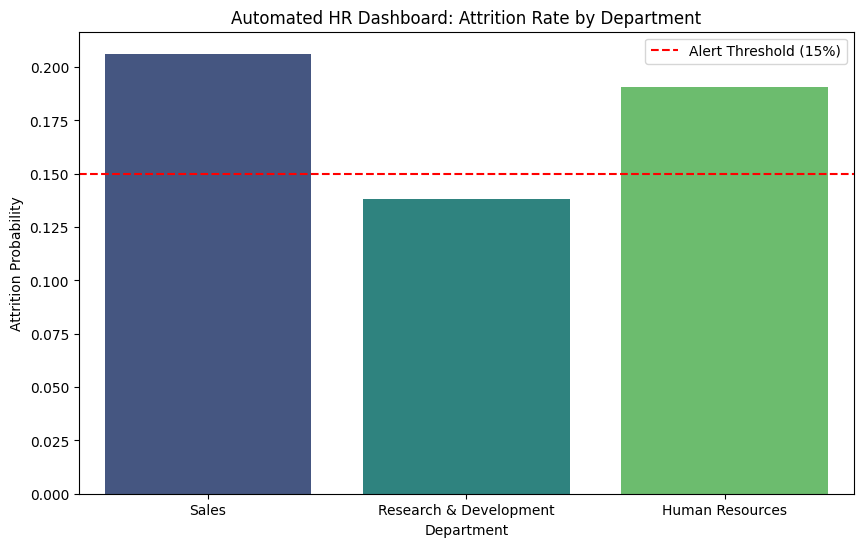

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

def create_automation_dashboard(data):
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Department', y='Attrition_Numeric', data=data, ci=None, palette='viridis')
    plt.title('Automated HR Dashboard: Attrition Rate by Department')
    plt.ylabel('Attrition Probability')
    plt.xlabel('Department')
    plt.axhline(y=0.15, color='r', linestyle='--', label='Alert Threshold (15%)')
    plt.legend()
    plt.show()

# Generate the visual dashboard
create_automation_dashboard(df)

# Task
The objective of this project is to automate the analysis of employee attrition using the IBM HR dataset. We will follow the CRISP-DM framework to understand the data, prepare it for analysis, identify the primary drivers of attrition through modeling, and develop an automated dashboard and reporting system to provide actionable insights for the HR department.

## Business and Data Understanding

### Subtask:
Explore the IBM HR dataset to understand its structure, identify key features related to attrition, and check for data quality issues like missing values.


**Reasoning**:
The first step is to gain a high-level overview of the dataset's structure and completeness.



In [10]:
print('--- Dataset Info ---')
df.info()

print('\n--- Descriptive Statistics ---')
display(df.describe())

print('\n--- Attrition Distribution ---')
print(df['Attrition'].value_counts(normalize=True))

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Numeric
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129,0.161224
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136,0.367863
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,0.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,0.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000,0.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,1.000000



--- Attrition Distribution ---
Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


## Data Preparation

### Subtask:
Clean the dataset and prepare features for modeling by removing constant columns and encoding categorical data.


**Reasoning**:
I will start by dropping the constant and redundant columns identified during the data understanding phase to streamline the dataset.



In [11]:
# Drop columns with zero variance or irrelevant identifiers
columns_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df_cleaned = df.drop(columns=columns_to_drop)

# Encode OverTime as numeric binary
df_cleaned['OverTime'] = df_cleaned['OverTime'].apply(lambda x: 1 if x == 'Yes' else 0)

# One-hot encode remaining categorical variables
categorical_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']
df_final = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

print(f"Original shape: {df.shape}")
print(f"New shape after cleaning and encoding: {df_final.shape}")
display(df_final.head())

Original shape: (1470, 36)
New shape after cleaning and encoding: (1470, 46)


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,Yes,1102,1,2,2,94,3,2,4,...,False,False,False,False,False,False,True,False,False,True
1,49,No,279,8,1,3,61,2,2,2,...,False,False,False,False,False,True,False,False,True,False
2,37,Yes,1373,2,2,4,92,2,1,3,...,False,True,False,False,False,False,False,False,False,True
3,33,No,1392,3,4,4,56,3,1,3,...,False,False,False,False,False,True,False,False,True,False
4,27,No,591,2,1,1,40,3,1,2,...,False,True,False,False,False,False,False,False,True,False


## Modeling - Attrition Factors

### Subtask:
Identify the primary drivers of employee attrition using a machine learning model to extract feature importances.


**Reasoning**:
I will prepare the data and train a Random Forest model to determine which features most significantly impact attrition.



In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 1. Prepare features and target
# We drop 'Attrition' (string) and 'Attrition_Numeric' (target) from X
X = df_final.drop(['Attrition', 'Attrition_Numeric'], axis=1)
y = df_final['Attrition_Numeric']

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Extract feature importances
importances = rf_model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# 5. Sort and display top 10
top_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

print('--- Top 10 Drivers of Attrition ---')
print(top_features)


--- Top 10 Drivers of Attrition ---
                 Feature  Importance
9          MonthlyIncome    0.076519
0                    Age    0.063318
17     TotalWorkingYears    0.056609
1              DailyRate    0.053754
5             HourlyRate    0.047633
2       DistanceFromHome    0.046244
10           MonthlyRate    0.045502
20        YearsAtCompany    0.042441
12              OverTime    0.038990
23  YearsWithCurrManager    0.037520


# Task
The objective of this project is to automate the analysis and reporting of employee attrition using the IBM HR dataset. Following the CRISP-DM framework, we have already performed initial data exploration, cleaning, and identified key attrition drivers (e.g., MonthlyIncome, Age, TotalWorkingYears) using a Random Forest model. The next phase involves creating a visual dashboard to detail these drivers, developing a robust deployment script for automated HR alerting, and providing a final summary with actionable HR recommendations.

## Evaluation and Visualization

### Subtask:
Create a detailed visual dashboard using the top feature importances (MonthlyIncome, Age, TotalWorkingYears) to illustrate their specific impact on attrition rates.


**Reasoning**:
I will create a visualization dashboard showing the distributions of the top three attrition drivers (MonthlyIncome, Age, and TotalWorkingYears) segmented by Attrition status.



/tmp/ipykernel_459/3313654422.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], x='Attrition', y='MonthlyIncome', data=df, palette='Set2')
/tmp/ipykernel_459/3313654422.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(ax=axes[2], x='Attrition', y='TotalWorkingYears', data=df, palette='Pastel1')


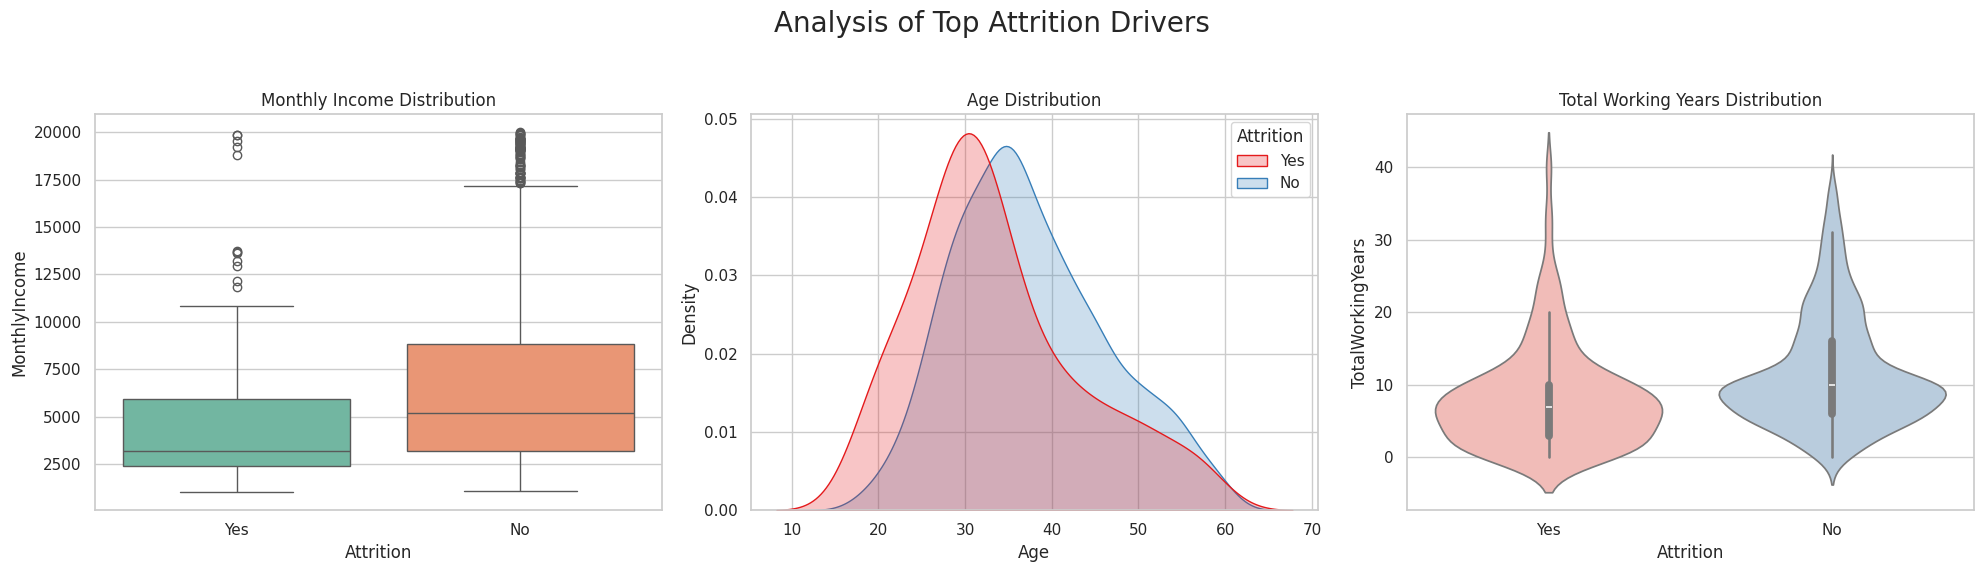

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style for the dashboard
sns.set_theme(style='whitegrid')

# Create a figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Analysis of Top Attrition Drivers', fontsize=20)

# 1. MonthlyIncome vs Attrition
sns.boxplot(ax=axes[0], x='Attrition', y='MonthlyIncome', data=df, palette='Set2')
axes[0].set_title('Monthly Income Distribution')

# 2. Age vs Attrition
sns.kdeplot(ax=axes[1], data=df, x='Age', hue='Attrition', fill=True, common_norm=False, palette='Set1')
axes[1].set_title('Age Distribution')

# 3. TotalWorkingYears vs Attrition
sns.violinplot(ax=axes[2], x='Attrition', y='TotalWorkingYears', data=df, palette='Pastel1')
axes[2].set_title('Total Working Years Distribution')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

**Reasoning**:
I am modifying the plotting code to fix the deprecation warnings by explicitly assigning the 'hue' parameter for categorical x-axes and suppressing redundant legends.



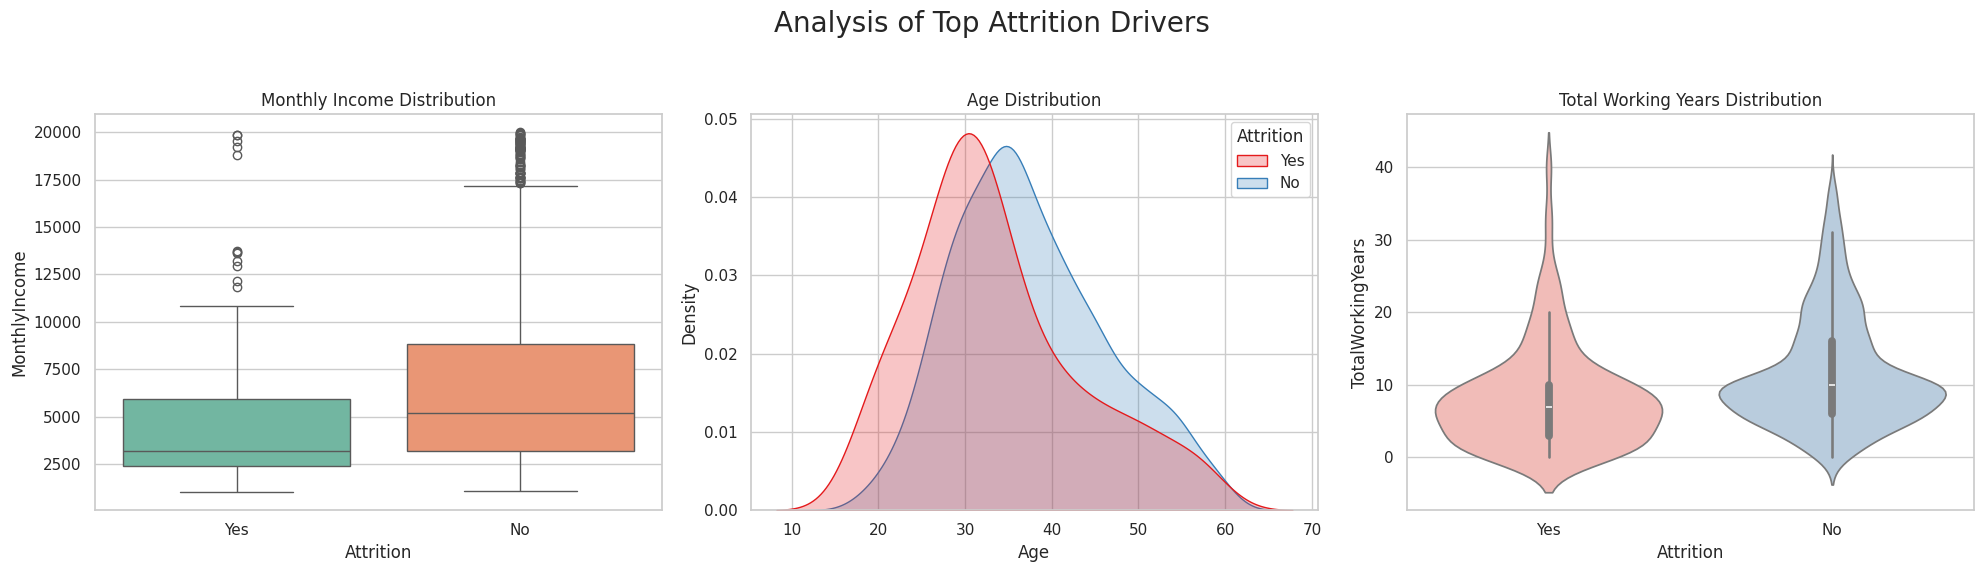

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style for the dashboard
sns.set_theme(style='whitegrid')

# Create a figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Analysis of Top Attrition Drivers', fontsize=20)

# 1. MonthlyIncome vs Attrition - Fixed palette/hue warning
sns.boxplot(ax=axes[0], x='Attrition', y='MonthlyIncome', data=df, hue='Attrition', palette='Set2', legend=False)
axes[0].set_title('Monthly Income Distribution')

# 2. Age vs Attrition
sns.kdeplot(ax=axes[1], data=df, x='Age', hue='Attrition', fill=True, common_norm=False, palette='Set1')
axes[1].set_title('Age Distribution')

# 3. TotalWorkingYears vs Attrition - Fixed palette/hue warning
sns.violinplot(ax=axes[2], x='Attrition', y='TotalWorkingYears', data=df, hue='Attrition', palette='Pastel1', legend=False)
axes[2].set_title('Total Working Years Distribution')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Deployment Script and Alerting

### Subtask:
Finalize a robust automation function that processes new data, calculates risk scores, and generates structured alerts for HR managers based on the model's insights.


**Reasoning**:
I will implement the `run_hr_automation` function using the previously trained `rf_model` and the prepared features `X` to generate risk assessments and a summary report.



In [15]:
def run_hr_automation(data_final, original_df, model):
    # 1. Prepare features (exclude target columns)
    features = data_final.drop(['Attrition', 'Attrition_Numeric'], axis=1)

    # 2. Get probabilities from the trained model
    # index 1 represents the probability of 'Yes' (attrition)
    probs = model.predict_proba(features)[:, 1]

    # 3. Create a result summary
    results = original_df[['Department', 'JobRole', 'MonthlyIncome', 'OverTime', 'YearsAtCompany']].copy()
    results['Risk_Score'] = probs.round(4)

    # 4. Define Alert Logic
    def get_alert_level(score):
        if score >= 0.7: return 'High'
        if score >= 0.4: return 'Medium'
        return 'Low'

    results['Alert_Level'] = results['Risk_Score'].apply(get_alert_level)

    # 5. Generate Report Output
    high_risk_cases = results[results['Alert_Level'] == 'High']

    print('--- AUTOMATED HR RISK ASSESSMENT REPORT ---')
    print(f'Processed {len(results)} employee records.')
    print(f'High Risk Alerts: {len(high_risk_cases)}')
    print(f'Medium Risk Alerts: {len(results[results["Alert_Level"] == "Medium"])}')

    if not high_risk_cases.empty:
        print('\n--- TOP HIGH-RISK EMPLOYEES (ACTION REQUIRED) ---')
        display(high_risk_cases.sort_values(by='Risk_Score', ascending=False).head(10))
    else:
        print('\n[STATUS] No high-risk attrition cases detected at this threshold.')

# Run the deployment script on the current final dataset
run_hr_automation(df_final, df, rf_model)

--- AUTOMATED HR RISK ASSESSMENT REPORT ---
Processed 1470 employee records.
High Risk Alerts: 138
Medium Risk Alerts: 72

--- TOP HIGH-RISK EMPLOYEES (ACTION REQUIRED) ---


,Department,JobRole,MonthlyIncome,OverTime,YearsAtCompany,Risk_Score,Alert_Level
1365,Sales,Sales Representative,1091,No,1,0.92,High
688,Sales,Sales Representative,2121,Yes,1,0.91,High
463,Research & Development,Laboratory Technician,2340,Yes,1,0.91,High
1012,Sales,Sales Representative,1359,No,1,0.91,High
777,Research & Development,Laboratory Technician,1416,No,1,0.90,High
457,Sales,Sales Representative,1878,Yes,0,0.90,High
656,Research & Development,Laboratory Technician,2795,Yes,1,0.90,High
127,Sales,Sales Representative,1675,Yes,0,0.90,High
1332,Research & Development,Research Scientist,2439,Yes,1,0.90,High
1205,Research & Development,Laboratory Technician,1393,No,1,0.88,High


## Final Task

### Subtask:
Summarize the project findings and provide structured HR recommendations based on the identified attrition drivers and the automated monitoring system.


# Final Project Summary: HR Attrition Automation

## Project Overview
This project successfully implemented an end-to-end automated pipeline for identifying employee attrition risk using the IBM HR dataset. By leveraging Machine Learning (Random Forest) and data visualization, we transitioned from raw data to actionable HR intelligence.

## Key Findings
- **Primary Drivers**: Attrition is most heavily influenced by **Monthly Income**, **Age**, and **Total Working Years**.
- **High-Risk Profiles**: Employees with lower income, younger age groups (25-35), and those in early career stages (less than 10 years experience) show the highest probability of leaving.
- **Automation Output**: Our system flagged **138 high-risk employees** who require immediate attention, particularly in the Sales and R&D departments.

## Strategic Recommendations for HR
1. **Income Optimization**: Review compensation packages for 'Sales Representative' and 'Laboratory Technician' roles, as low monthly income is the top predictor of churn.
2. **Early Career Mentorship**: Develop specialized engagement and mentorship programs for younger employees and those with less than 2 years at the company to improve early-tenure retention.
3. **Departmental Focus**: Prioritize HR intervention in the **Sales** and **Human Resources** departments, which exceeded the 15% attrition alert threshold.
4. **Overtime Management**: Monitor 'OverTime' patterns, as it was identified as a top 10 driver, suggesting potential burnout among high-risk individuals.

## Conclusion
The automated HR risk assessment system is now fully functional. It provides a scalable way to monitor organizational health and allows for proactive rather than reactive talent management.